# Week 10 - Clustering, Part 1: K-Means

Weeks 4-9 were supervised: every model was told which orders were profitable, which reviews were negative, and which items were reordered. K-Means is **unsupervised**: it gets only the features and has to find groups on its own. It picks *k* centroids, assigns every point to the nearest one (Euclidean distance), moves each centroid to the mean of its points, and repeats until nothing changes. It minimizes **inertia**, the total squared distance from each point to its centroid.

The reading's four ideas, and where each shows up:

| Idea | Where |
|---|---|
| **Feature scaling** - K-Means is a distance method, so a feature in the thousands swamps a feature between 0 and 1 (the Week 8 KNN lesson again) | Part 0, A2 |
| **Elbow method** - inertia always falls as *k* grows; look for the bend where it stops falling fast | A3, B1, C1 |
| **Silhouette score** - for each point, (b - a) / max(a, b), where a = mean distance to its own cluster and b = mean distance to the nearest other cluster; ranges from -1 to 1 | A3, A4, B1, C1 |
| **Distance metrics** - Euclidean (what K-Means optimizes), Manhattan, cosine | Part 0, A6, Part C |

| Dataset | What gets clustered | Question |
|---|---|---|
| E-commerce (`ecommerce_data.csv`) | 3,312 orders on `Sales`, `Quantity`, `Discount` | Without ever seeing `Profit`, does K-Means find the money-losing orders? |
| Instacart (`insta_df_sample.csv`) | 70 aisles, each summarized by how its items are bought | Are there "staple" vs. "occasional" aisles (useful for the recommender in my proposal)? |
| Amazon reviews (`amazon_review_data.csv`) | 9,357 reviews as TF-IDF vectors | Do reviews form topic clusters, and do any of them concentrate the negative reviews? |

The labels (profitable, reordered, negative) are **never** passed to K-Means; I only use them afterward to describe the clusters.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler, MinMaxScaler, normalize
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score
from sklearn.metrics.pairwise import pairwise_distances
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD

warnings.filterwarnings("ignore")
np.random.seed(42)
BLUE, ORANGE, GREY, GREEN = "#2a78d6", "#eb6834", "#8a8984", "#1b9e77"
PALETTE = [BLUE, ORANGE, GREEN, "#7b4fb8", GREY, "#c9a227", "#d6457a", "#3fb0c8"]

def k_sweep(A, ks, metric="euclidean", sample=None, seed=42):
    # inertia and silhouette for each k; silhouette can be computed on a sample to save time
    rows = []
    idx = np.random.default_rng(seed).choice(len(A), sample, replace=False) if sample else np.arange(len(A))
    for k in ks:
        km = KMeans(n_clusters=k, n_init=10, random_state=seed).fit(A)
        rows.append({"k": k, "inertia": km.inertia_, "silhouette": silhouette_score(A[idx], km.labels_[idx], metric=metric),
                     "sizes": np.bincount(km.labels_).tolist()})
    return pd.DataFrame(rows)

## Part 0 - Warm-up: scaling and distance on toy data

Two synthetic groups that differ only in a small-scale feature (think `Discount`, 0 to 0.8), plus a large-scale feature that is pure noise (think `Sales`, in the hundreds). K-Means on the raw values should split along the noisy feature, because that is where the squared distances are.

In [2]:
rng = np.random.default_rng(0)
n = 300
group = np.repeat([0, 1], n // 2)
toy = np.column_stack([rng.normal(500, 200, n),                    # large-scale noise
                       np.where(group == 0, 0.1, 0.6) + rng.normal(0, 0.05, n)])  # small-scale real signal
for name, A in [("raw", toy), ("standardized", StandardScaler().fit_transform(toy))]:
    lab = KMeans(2, n_init=10, random_state=42).fit_predict(A)
    print(f"{name:12s}: agreement with the true groups (ARI) = {adjusted_rand_score(group, lab):.3f}")

# distance metrics on two simple vectors
p, q = np.array([[1.0, 2.0]]), np.array([[4.0, 6.0]])
for m in ["euclidean", "manhattan", "cosine"]:
    print(f"{m:9s} distance between (1,2) and (4,6): {pairwise_distances(p, q, metric=m)[0, 0]:.3f}")

raw         : agreement with the true groups (ARI) = 0.022


standardized: agreement with the true groups (ARI) = 1.000
euclidean distance between (1,2) and (4,6): 5.000
manhattan distance between (1,2) and (4,6): 7.000
cosine    distance between (1,2) and (4,6): 0.008


## Part A - E-commerce orders

### A1. Choosing the features (what the EDA said)

I cluster on the three numeric order features only. One-hot category columns would add 26 binary dimensions, and Week 8 showed they made KNN *worse* (the curse of dimensionality), so they are left out and used only to describe the clusters afterward. `Profit` is left out on purpose so the clustering cannot cheat.

The Week 1 and Milestone One EDA showed that `Sales` is extremely right-skewed (a handful of orders over $5,000, most under $100). Squared Euclidean distance would let those few orders control the centroids, so I also try `log(1 + Sales)`.

In [3]:
df = pd.read_csv("ecommerce_data.csv")
profitable = (df["Profit"] > 0).astype(int).values        # used ONLY to describe clusters afterward
raw = df[["Sales", "Quantity", "Discount"]].copy()
logged = raw.assign(Sales=np.log1p(raw["Sales"])).rename(columns={"Sales": "log_Sales"})
print(raw.describe().round(2).T[["mean", "std", "min", "50%", "max"]])
print(f"\nSales skewness: raw {raw['Sales'].skew():.1f}, after log1p {logged['log_Sales'].skew():.2f}")

            mean     std   min    50%       max
Sales     221.38  585.26  0.44  53.81  13999.96
Quantity    3.77    2.22  1.00   3.00     14.00
Discount    0.16    0.21  0.00   0.20      0.80

Sales skewness: raw 10.6, after log1p 0.29


### A2. Feature scaling: four versions of the same data

Same K-Means (k = 3, 10 random starts) on four representations. I report the silhouette score **and the cluster sizes**, because a high silhouette can come from a degenerate split, and **how well the clusters separate profitable from unprofitable orders** (the best "purity": the largest share of unprofitable orders captured by any one cluster, together with that cluster's profitable rate).

In [4]:
reps = {
    "raw (no scaling)": raw.values,
    "min-max scaled": MinMaxScaler().fit_transform(raw),
    "standardized": StandardScaler().fit_transform(raw),
    "log(Sales) + standardized": StandardScaler().fit_transform(logged),
}
rows = []
for name, A in reps.items():
    km = KMeans(3, n_init=10, random_state=42).fit(A)
    lab = km.labels_
    unprof_share = [((lab == c) & (profitable == 0)).sum() / (profitable == 0).sum() for c in range(3)]
    best = int(np.argmax(unprof_share))
    rows.append({"representation": name, "silhouette": silhouette_score(A, lab), "cluster sizes": sorted(np.bincount(lab).tolist(), reverse=True),
                 "share of all unprofitable orders in one cluster": unprof_share[best], "that cluster's profitable rate": profitable[lab == best].mean()})
scaling_tbl = pd.DataFrame(rows).set_index("representation")
print(scaling_tbl.round(3).to_string())

                           silhouette      cluster sizes  share of all unprofitable orders in one cluster  that cluster's profitable rate
representation                                                                                                                           
raw (no scaling)                0.872     [3172, 136, 4]                                            0.962                           0.806
min-max scaled                  0.434   [2033, 915, 364]                                            0.560                           0.016
standardized                    0.485   [2353, 646, 313]                                            0.488                           0.003
log(Sales) + standardized       0.345  [1773, 1244, 295]                                            0.462                           0.000


The raw data has by far the highest silhouette, and it is the least useful clustering. With `Sales` in the thousands, the distances are essentially `Sales` distances, so K-Means puts almost every order in one cluster and gives a few huge orders their own clusters. Those few are very far from everything else, which is exactly what silhouette rewards. **A high silhouette score is not the same thing as a useful clustering**, and the cluster sizes are the quickest way to catch it. From here on I use the last representation, log(Sales) plus standardization.

### A3. Elbow method and silhouette score: choosing *k*

 k  inertia  silhouette                                              sizes
 2 7110.229       0.284                                       [1807, 1505]
 3 4908.070       0.345                                  [295, 1773, 1244]
 4 3682.532       0.350                             [1400, 519, 1101, 292]
 5 3170.913       0.332                         [1129, 297, 952, 644, 290]
 6 2833.878       0.326                    [274, 537, 568, 1023, 610, 300]
 7 2564.114       0.315                [494, 526, 272, 558, 251, 535, 676]
 8 2302.483       0.317           [550, 534, 115, 252, 169, 492, 676, 524]
 9 2092.135       0.316      [436, 439, 180, 330, 507, 543, 567, 106, 204]
10 1931.703       0.315 [169, 433, 127, 286, 552, 115, 442, 448, 478, 262]


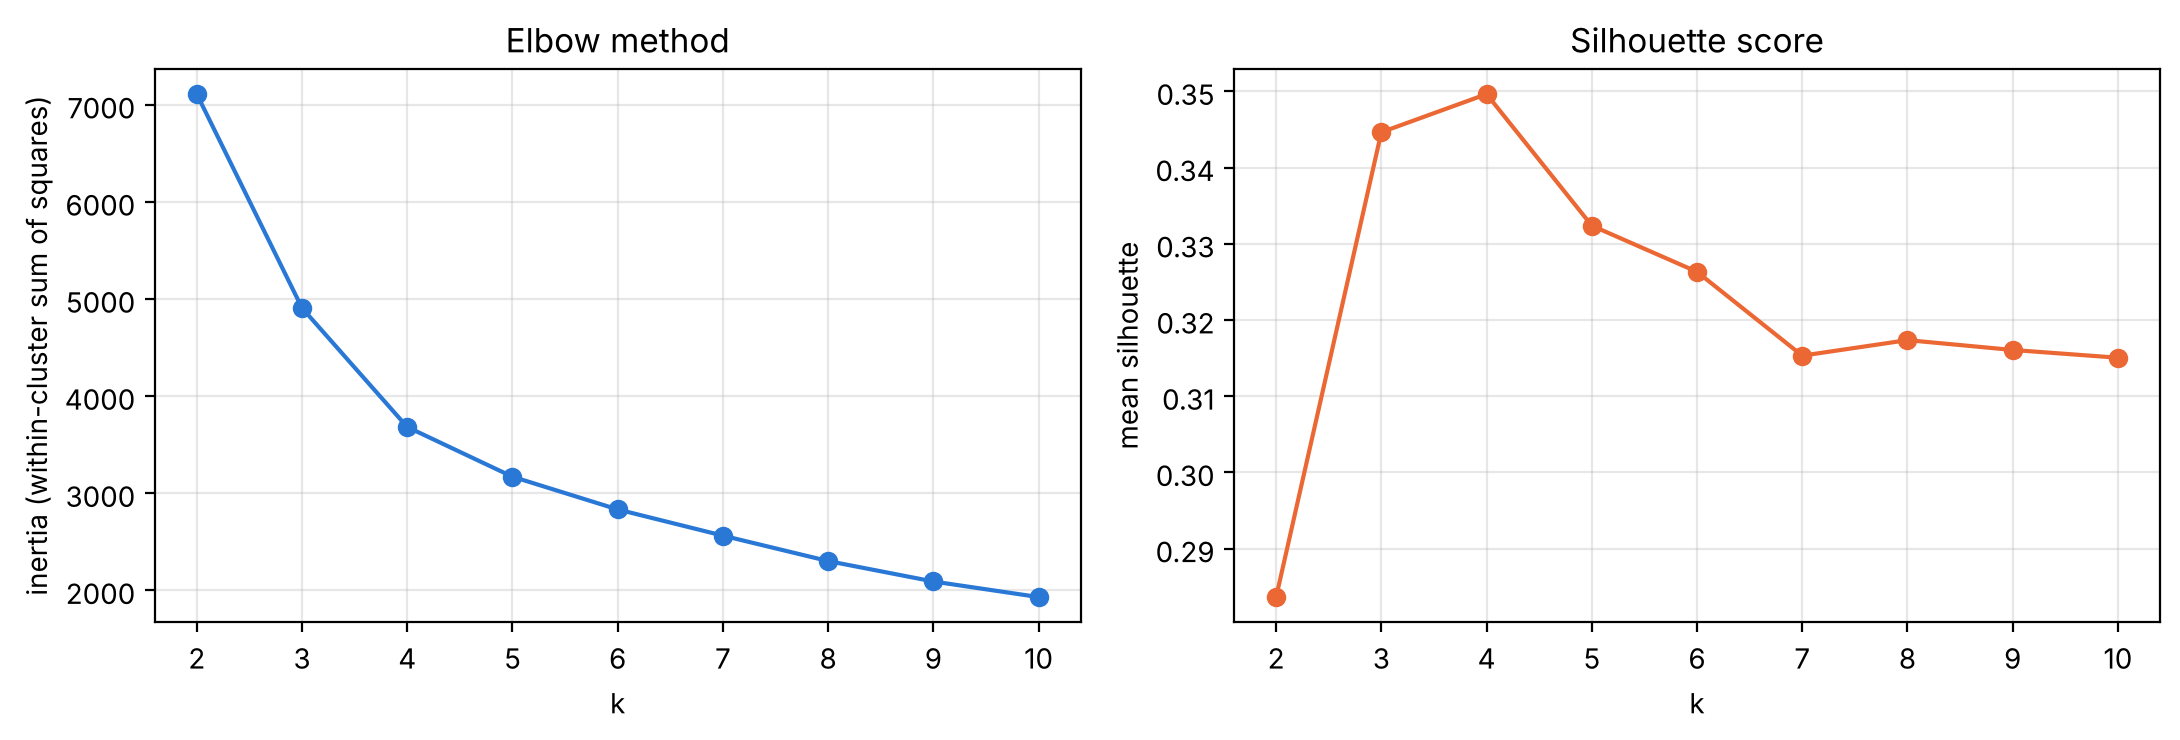

percent drop in inertia from k to k+1: {2: 31.0, 3: 25.0, 4: 13.9, 5: 10.6, 6: 9.5, 7: 10.2, 8: 9.1, 9: 7.7}


In [5]:
A = reps["log(Sales) + standardized"]
sweep = k_sweep(A, range(2, 11))
print(sweep.round(3).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(sweep.k, sweep.inertia, "-o", color=BLUE); ax[0].set_xlabel("k"); ax[0].set_ylabel("inertia (within-cluster sum of squares)"); ax[0].set_title("Elbow method")
ax[1].plot(sweep.k, sweep.silhouette, "-o", color=ORANGE); ax[1].set_xlabel("k"); ax[1].set_ylabel("mean silhouette"); ax[1].set_title("Silhouette score")
for a in ax: a.set_xticks(range(2, 11)); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

drops = -np.diff(sweep.inertia) / sweep.inertia[:-1] * 100
print("percent drop in inertia from k to k+1:", dict(zip(sweep.k[:-1], drops.round(1))))

### A4. Silhouette plot for the leading candidates

The mean silhouette hides which clusters are tight and which are loose. A per-point silhouette plot shows every order's score, grouped by cluster.

k=3: per-cluster mean silhouette {0: np.float64(0.452), 1: np.float64(0.424), 2: np.float64(0.206)} | share of orders with negative silhouette 0.044


k=4: per-cluster mean silhouette {0: np.float64(0.399), 1: np.float64(0.273), 2: np.float64(0.298), 3: np.float64(0.444)} | share of orders with negative silhouette 0.014


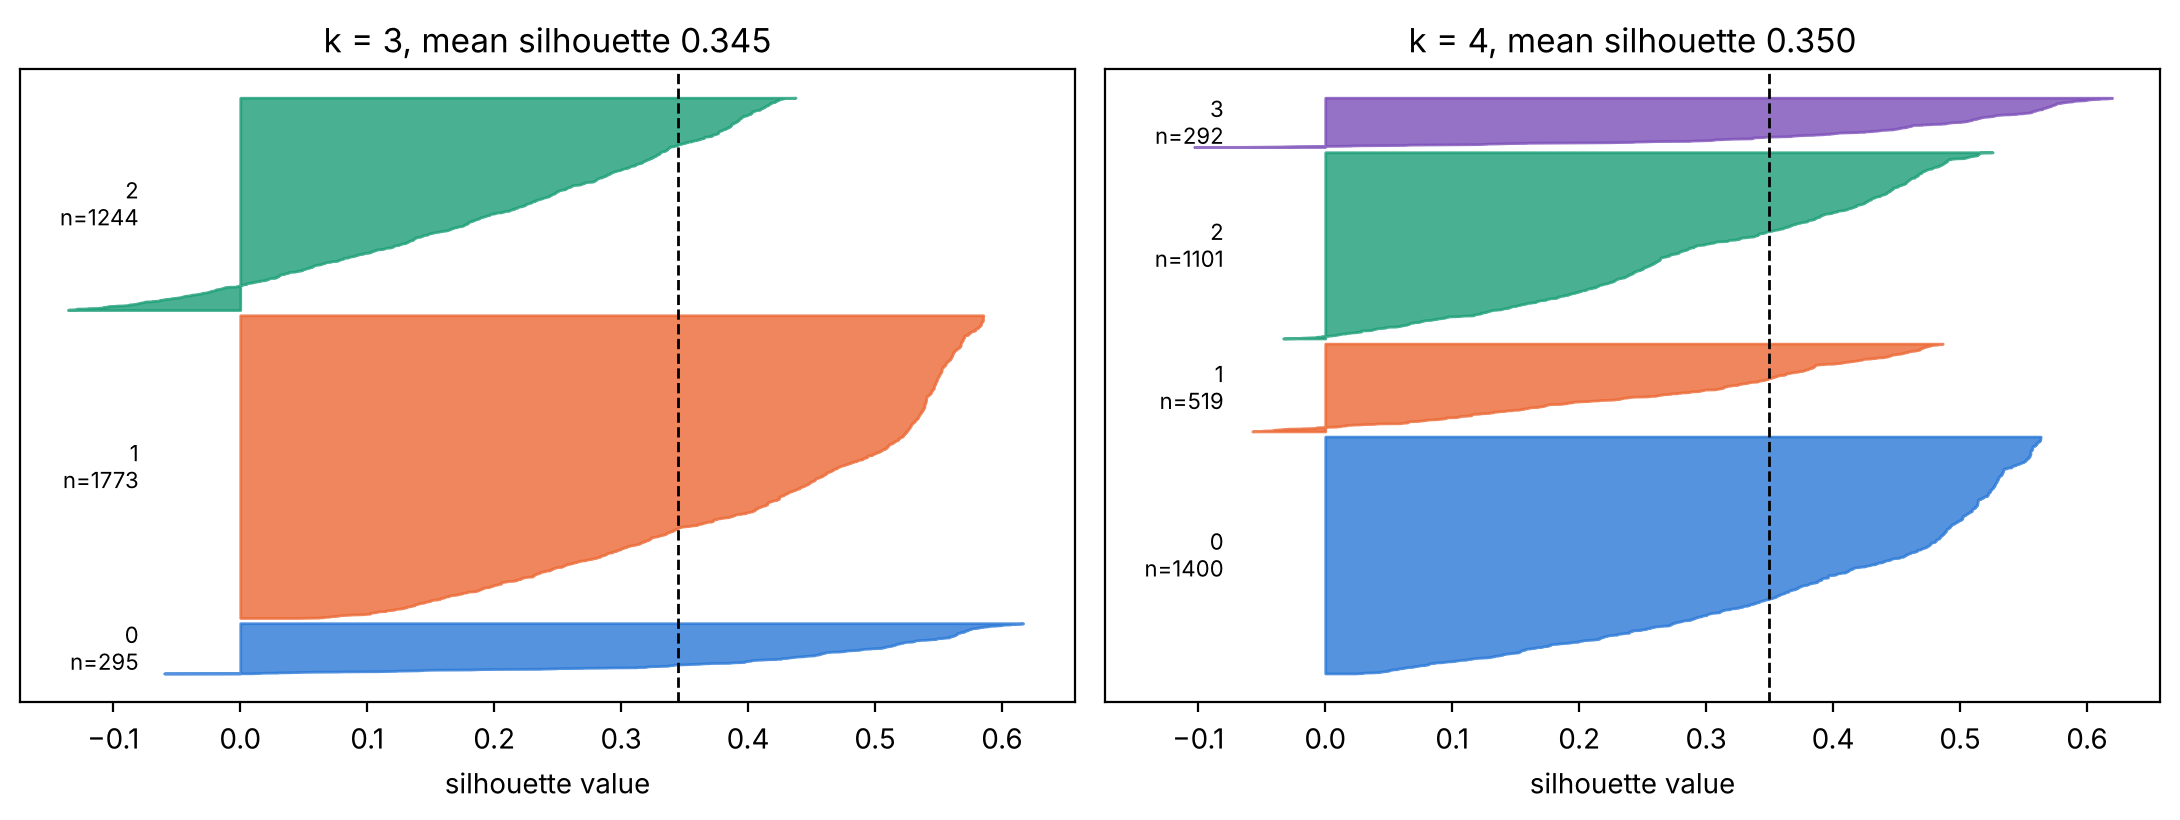

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharex=True)
for ax, k in zip(axes, [3, 4]):
    lab = KMeans(k, n_init=10, random_state=42).fit_predict(A)
    s = silhouette_samples(A, lab); y0 = 0
    for c in range(k):
        v = np.sort(s[lab == c]); ax.fill_betweenx(np.arange(y0, y0 + len(v)), 0, v, color=PALETTE[c], alpha=0.8)
        ax.text(-0.08, y0 + len(v) / 2, f"{c}\nn={len(v)}", fontsize=8, va="center", ha="right"); y0 += len(v) + 30
    ax.axvline(s.mean(), color="black", ls="--", lw=1); ax.set_title(f"k = {k}, mean silhouette {s.mean():.3f}"); ax.set_yticks([]); ax.set_xlabel("silhouette value")
    print(f"k={k}: per-cluster mean silhouette", {c: round(s[lab == c].mean(), 3) for c in range(k)}, "| share of orders with negative silhouette", round((s < 0).mean(), 3))
plt.tight_layout(); plt.show()

### A5. What are the clusters? (profiles, using `Profit` only now)

In [7]:
def profile(k):
    lab = KMeans(k, n_init=10, random_state=42).fit_predict(A)
    t = df.assign(cluster=lab, profitable=profitable).groupby("cluster").agg(
        orders=("profitable", "size"), profitable_rate=("profitable", "mean"), mean_discount=("Discount", "mean"),
        median_sales=("Sales", "median"), mean_quantity=("Quantity", "mean"), total_profit=("Profit", "sum"))
    return lab, t.sort_values("mean_discount", ascending=False)

lab3, prof3 = profile(3); lab4, prof4 = profile(4)
print("k = 3"); print(prof3.round(3).to_string())
print("\nk = 4"); print(prof4.round(3).to_string())

hi = prof3.index[0]
print(f"\nThe high-discount cluster (k=3): {prof3.loc[hi, 'orders']} orders, discount range "
      f"{df.Discount[lab3 == hi].min():.2f}-{df.Discount[lab3 == hi].max():.2f}, profitable rate {prof3.loc[hi, 'profitable_rate']:.3f}, total profit ${prof3.loc[hi, 'total_profit']:,.0f}")
print(f"Orders with discount >= 0.5 in the whole data: {(df.Discount >= 0.5).sum()}, profitable rate {profitable[df.Discount >= 0.5].mean():.3f}")
print("\nTop sub-categories in the high-discount cluster:"); print(df["Sub-Category"][lab3 == hi].value_counts().head(5).to_string())

k = 3
         orders  profitable_rate  mean_discount  median_sales  mean_quantity  total_profit
cluster                                                                                   
0           295            0.000          0.715        12.864          3.912    -27764.863
2          1244            0.842          0.109       254.752          5.375    104303.309
1          1773            0.917          0.097        25.344          2.614     16900.824

k = 4
         orders  profitable_rate  mean_discount  median_sales  mean_quantity  total_profit
cluster                                                                                   
3           292            0.000          0.715        12.440          3.866    -27432.185
2          1101            0.791          0.120       220.960          3.277     82109.510
1           519            0.902          0.101       119.700          7.622     29199.340
0          1400            0.953          0.089        18.689          2.702 

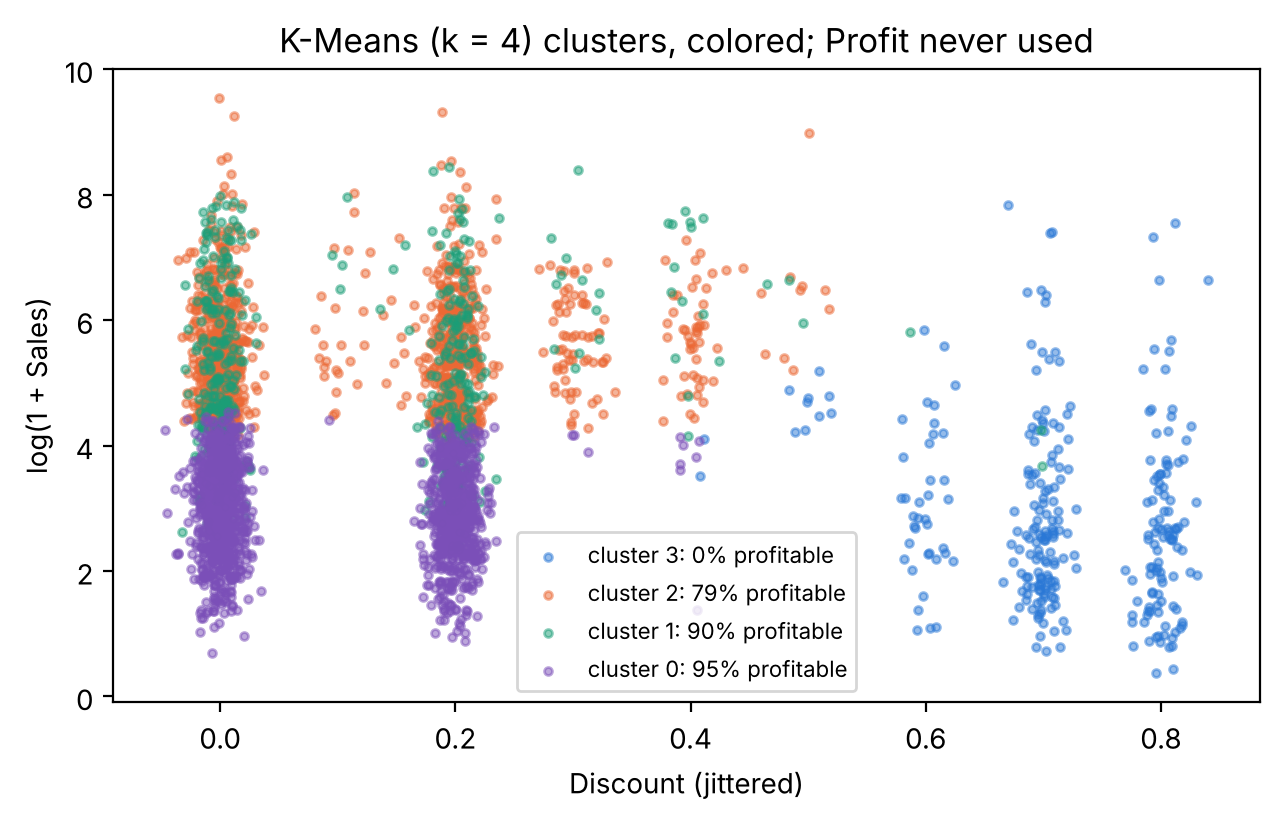

In [8]:
fig, ax = plt.subplots(figsize=(6.5, 4.2))
for c in prof4.index:
    m = lab4 == c
    ax.scatter(df.Discount[m] + np.random.default_rng(c).normal(0, 0.012, m.sum()), np.log1p(df.Sales[m]), s=8, alpha=0.5, color=PALETTE[list(prof4.index).index(c)],
               label=f"cluster {c}: {prof4.loc[c, 'profitable_rate']:.0%} profitable")
ax.set_xlabel("Discount (jittered)"); ax.set_ylabel("log(1 + Sales)"); ax.set_title("K-Means (k = 4) clusters, colored; Profit never used"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

### A6. Distance metrics and stability

K-Means is built on squared Euclidean distance (the mean is the point that minimizes it), so it cannot simply be switched to Manhattan or cosine. What *can* change is the metric used to judge the result. I score the k = 3 and k = 4 labels with three metrics, to check that the ranking of the two does not depend on the metric.

Then a check on overfitting. Clustering has no test set, but the same idea applies: a real structure should come back when the data or the random start changes. I (1) re-run with 10 different random seeds, (2) fit on a random 75% of orders and assign the other 25% to the nearest centroid, then compare those assignments with a model fit on the full data (adjusted Rand index; 1 = identical, 0 = chance).

In [9]:
for m in ["euclidean", "manhattan", "cosine"]:
    print(f"silhouette measured with {m:9s} distance: k=3 {silhouette_score(A, lab3, metric=m):.3f} | k=4 {silhouette_score(A, lab4, metric=m):.3f}")

seed_ari = {k: np.mean([adjusted_rand_score(KMeans(k, n_init=1, random_state=0).fit_predict(A), KMeans(k, n_init=1, random_state=s).fit_predict(A)) for s in range(1, 11)]) for k in [2, 3, 4, 5, 6]}
print("\nmean ARI vs. seed 0 across 10 single-start runs:", {k: round(v, 3) for k, v in seed_ari.items()})

split_ari = {}
rng = np.random.default_rng(42)
for k in [2, 3, 4, 5, 6]:
    full = KMeans(k, n_init=10, random_state=42).fit(A)
    aris = []
    for rep in range(10):
        idx = rng.permutation(len(A)); tr, ho = idx[: int(0.75 * len(A))], idx[int(0.75 * len(A)):]
        part = KMeans(k, n_init=10, random_state=rep).fit(A[tr])
        aris.append(adjusted_rand_score(full.predict(A[ho]), part.predict(A[ho])))
    split_ari[k] = np.mean(aris)
print("held-out 25% agreement (ARI), 10 splits:", {k: round(v, 3) for k, v in split_ari.items()})

silhouette measured with euclidean distance: k=3 0.345 | k=4 0.350
silhouette measured with manhattan distance: k=3 0.339 | k=4 0.346


silhouette measured with cosine    distance: k=3 0.354 | k=4 0.397



mean ARI vs. seed 0 across 10 single-start runs: {2: np.float64(0.093), 3: np.float64(0.779), 4: np.float64(0.999), 5: np.float64(0.897), 6: np.float64(0.652)}


held-out 25% agreement (ARI), 10 splits: {2: np.float64(0.942), 3: np.float64(0.939), 4: np.float64(0.984), 5: np.float64(0.975), 6: np.float64(0.886)}


## Part B - Instacart: clustering aisles, not rows

The Instacart sample is 15,000 random rows out of 32 million, so almost every user and order appears only once; there is nothing to cluster at the user level. Aisles are different: each aisle has many rows, and summarizing *how* its items are bought (reorder rate, position in the cart, time of day, days since the previous order, how far into a customer's history) gives a behavioral fingerprint. I keep the 70 aisles with at least 40 rows so the averages are not noise, and standardize the five features.

This matters for my proposal's recommender: if aisles fall into "staples" and "occasional" groups, the recommender can treat them differently.

In [10]:
ins = pd.read_csv("insta_df_sample.csv")
aisles = (ins.groupby(["aisle", "department"])
             .agg(rows=("reordered", "size"), reorder_rate=("reordered", "mean"), cart_position=("add_to_cart_order", "mean"),
                  hour=("order_hour_of_day", "mean"), days_since_prior=("days_since_prior_order", "mean"), order_number=("order_number", "median"))
             .reset_index())
print(f"{len(aisles)} aisles in the sample; keeping those with >= 40 rows")
aisles = aisles[aisles.rows >= 40].reset_index(drop=True)
aisle_feats = ["reorder_rate", "cart_position", "hour", "days_since_prior", "order_number"]
Ai = StandardScaler().fit_transform(aisles[aisle_feats])
print(len(aisles), "aisles kept")
print("\ncorrelations between aisle features:"); print(aisles[aisle_feats].corr().round(2).to_string())

134 aisles in the sample; keeping those with >= 40 rows
70 aisles kept

correlations between aisle features:
                  reorder_rate  cart_position  hour  days_since_prior  order_number
reorder_rate              1.00          -0.65 -0.07             -0.02          0.10
cart_position            -0.65           1.00  0.05             -0.03          0.01
hour                     -0.07           0.05  1.00              0.02         -0.14
days_since_prior         -0.02          -0.03  0.02              1.00         -0.37
order_number              0.10           0.01 -0.14             -0.37          1.00


### B1. Elbow and silhouette

 k  inertia  silhouette                              sizes
 2  270.096       0.207                           [38, 32]
 3  215.604       0.222                       [26, 23, 21]
 4  186.515       0.224                   [18, 19, 14, 19]
 5  165.538       0.216               [18, 12, 12, 15, 13]
 6  154.028       0.205             [7, 11, 19, 9, 12, 12]
 7  138.082       0.217          [13, 8, 15, 11, 4, 6, 13]
 8  131.854       0.201       [6, 6, 13, 12, 12, 10, 6, 5]
 9  120.826       0.209    [10, 10, 14, 5, 3, 13, 5, 4, 6]
10  112.954       0.195 [11, 5, 12, 13, 4, 3, 10, 4, 4, 4]


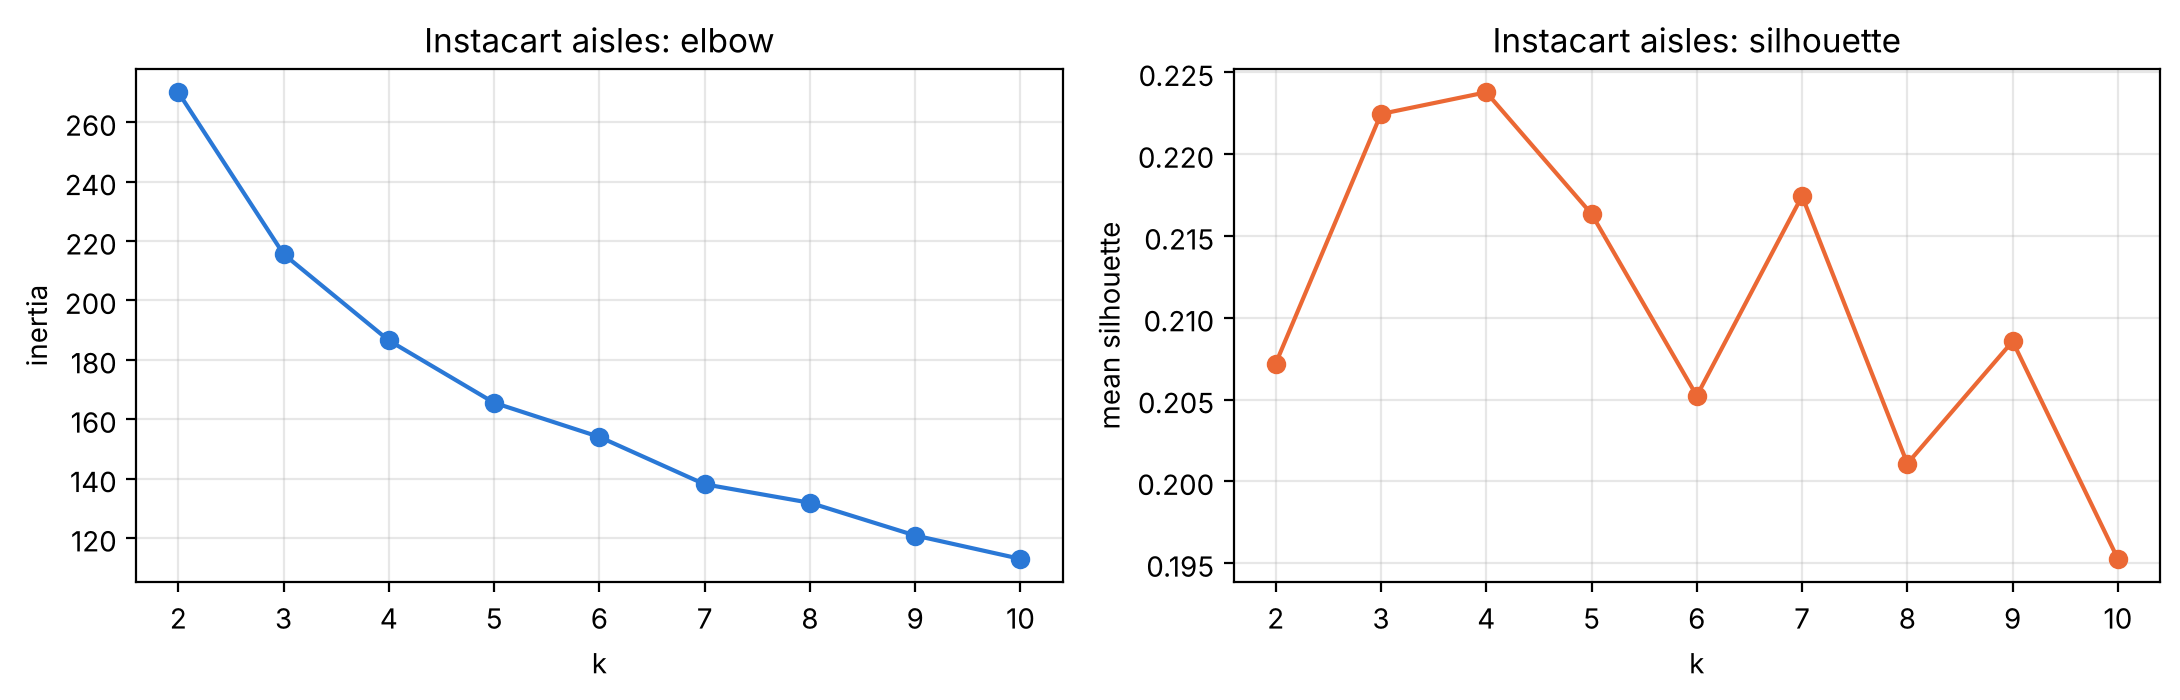

In [11]:
sweep_i = k_sweep(Ai, range(2, 11))
print(sweep_i.round(3).to_string(index=False))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(sweep_i.k, sweep_i.inertia, "-o", color=BLUE); ax[0].set_title("Instacart aisles: elbow"); ax[0].set_ylabel("inertia")
ax[1].plot(sweep_i.k, sweep_i.silhouette, "-o", color=ORANGE); ax[1].set_title("Instacart aisles: silhouette"); ax[1].set_ylabel("mean silhouette")
for a in ax: a.set_xlabel("k"); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

### B2. Aisle clusters

In [12]:
ki = 3
km_i = KMeans(ki, n_init=20, random_state=42).fit(Ai)
aisles["cluster"] = km_i.labels_
summary_i = aisles.groupby("cluster").agg(aisles=("aisle", "size"), rows=("rows", "sum"), **{f: (f, "mean") for f in aisle_feats}).sort_values("reorder_rate", ascending=False)
print(summary_i.round(2).to_string())
for c in summary_i.index:
    print(f"\ncluster {c} (reorder rate {summary_i.loc[c, 'reorder_rate']:.2f}), largest aisles:",
          ", ".join(aisles[aisles.cluster == c].sort_values("rows", ascending=False).aisle.head(8)))
print(f"\nsilhouette at k={ki}: {silhouette_score(Ai, km_i.labels_):.3f}")

         aisles  rows  reorder_rate  cart_position   hour  days_since_prior  order_number
cluster                                                                                  
1            20  6136          0.66           7.05  13.37             10.81         11.78
2            27  5080          0.54           8.71  13.62             11.94          9.72
0            23  2776          0.45           9.98  13.46             10.57         11.98

cluster 1 (reorder rate 0.66), largest aisles: fresh fruits, packaged vegetables fruits, yogurt, milk, water seltzer sparkling water, soy lactosefree, refrigerated, eggs

cluster 2 (reorder rate 0.54), largest aisles: fresh vegetables, packaged cheese, chips pretzels, bread, ice cream ice, cereal, fresh dips tapenades, frozen meals

cluster 0 (reorder rate 0.45), largest aisles: frozen produce, energy granola bars, crackers, baby food formula, baking ingredients, soup broth bouillon, spreads, nuts seeds dried fruit

silhouette at k=3: 0.222


## Part C - Amazon reviews: K-Means on text with cosine distance

Same text preparation as Weeks 5, 8, and 9 (3-star reviews dropped, title + body, TF-IDF with unigrams and bigrams). Week 8 showed that cosine is the right distance for text, and that Euclidean and cosine agree once each vector has length 1. So I reduce the 8,000 TF-IDF columns to 100 dimensions with truncated SVD (latent semantic analysis), rescale each row to length 1, and run ordinary K-Means. On unit vectors, minimizing squared Euclidean distance is the same as maximizing cosine similarity. Silhouette is computed with the cosine metric on a 3,000-review sample.

In [13]:
a = pd.read_csv("amazon_review_data.csv")
a = a[a["rating"] != 3].copy()
a["negative"] = (a["rating"] <= 2).astype(int)
a["full"] = a["title"].fillna("") + ". " + a["text"].fillna("")
tfidf = TfidfVectorizer(stop_words="english", min_df=3, max_features=8000, ngram_range=(1, 2), sublinear_tf=True)
T = tfidf.fit_transform(a["full"])
keep = T.getnnz(axis=1) > 0                     # Week 8 lesson: all-zero vectors break distance methods
T, a = T[keep], a[keep].reset_index(drop=True)
svd = TruncatedSVD(n_components=100, random_state=42)
Z = normalize(svd.fit_transform(T))
print(T.shape, f"| reviews dropped for an empty vector: {(~keep).sum()} | variance kept by 100 SVD components: {svd.explained_variance_ratio_.sum():.1%}")

(9355, 8000) | reviews dropped for an empty vector: 18 | variance kept by 100 SVD components: 20.3%


 k  inertia  silhouette
 2 8466.210       0.059
 4 8098.480       0.045
 6 7831.196       0.068
 8 7603.947       0.083
10 7446.561       0.089
15 7037.547       0.118
20 6752.413       0.132


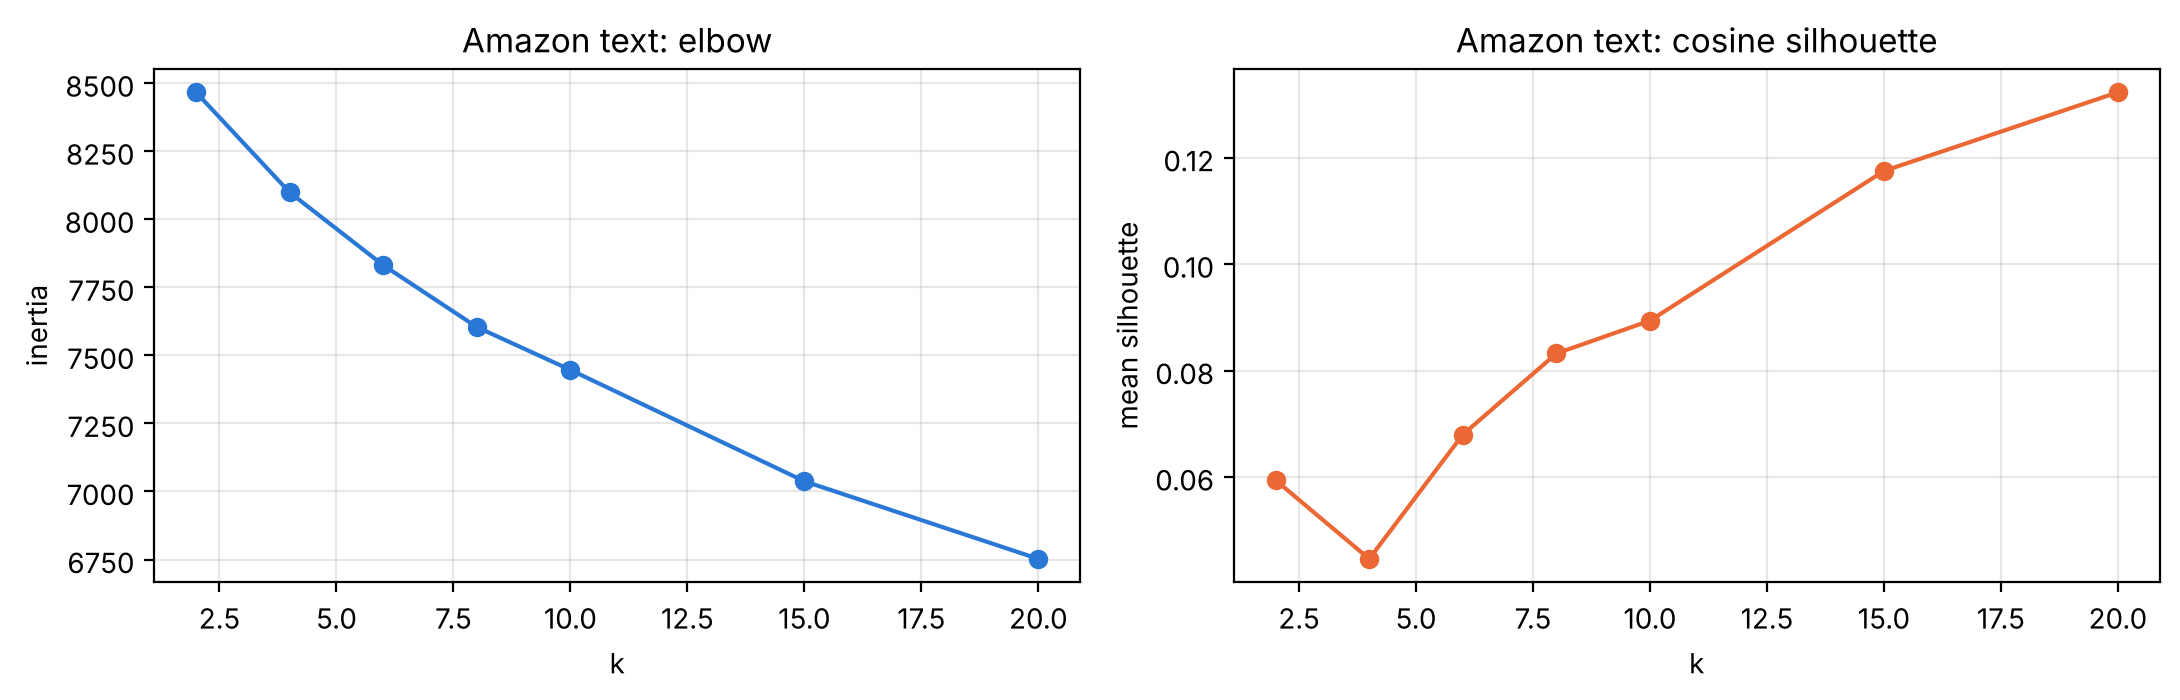

In [14]:
sweep_t = k_sweep(Z, [2, 4, 6, 8, 10, 15, 20], metric="cosine", sample=3000)
print(sweep_t[["k", "inertia", "silhouette"]].round(3).to_string(index=False))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(sweep_t.k, sweep_t.inertia, "-o", color=BLUE); ax[0].set_title("Amazon text: elbow"); ax[0].set_ylabel("inertia")
ax[1].plot(sweep_t.k, sweep_t.silhouette, "-o", color=ORANGE); ax[1].set_title("Amazon text: cosine silhouette"); ax[1].set_ylabel("mean silhouette")
for a_ in ax: a_.set_xlabel("k"); a_.grid(alpha=0.3)
plt.tight_layout(); plt.show()

In [15]:
kt = 8
km_t = KMeans(kt, n_init=10, random_state=42).fit(Z)
a["cluster"] = km_t.labels_
centroid_terms = svd.inverse_transform(km_t.cluster_centers_)
names = np.array(tfidf.get_feature_names_out())
rows = []
for c in range(kt):
    s = a[a.cluster == c]
    rows.append({"cluster": c, "reviews": len(s), "negative_rate": s.negative.mean(),
                 "top terms": ", ".join(names[np.argsort(centroid_terms[c])[::-1][:7]]),
                 "top categories": ", ".join(s.category_name.value_counts().head(2).index)})
text_clusters = pd.DataFrame(rows).sort_values("negative_rate", ascending=False)
pd.set_option("display.max_colwidth", 90)
print(text_clusters.round(3).to_string(index=False))
print(f"\noverall negative rate: {a.negative.mean():.3f}")

 cluster  reviews  negative_rate                                                            top terms                                         top categories
       5     4046          0.209                         like, nice, just, use, really, perfect, easy                               Pet_Supplies, Gift_Cards
       0      804          0.149                              br, br br, like, good, use, just, album       Health_and_Personal_Care, Magazine_Subscriptions
       6      868          0.084 good, good quality, quality, good product, product, price, good good                  Grocery_and_Gourmet_Food, Video_Games
       2      409          0.081                   book, read, story, books, enjoyed, reading, series                                    Kindle_Store, Books
       7      311          0.048        reviews, useful, info, update, new, hesitate update, hesitate Industrial_and_Scientific, Cell_Phones_and_Accessories
       4      584          0.048        stars, stars great

## Conclusions

**Scaling decides what K-Means sees (Part 0, A2).** On the toy data, K-Means on raw values ignored the real signal (agreement with the true groups, ARI 0.022) and recovered it perfectly once standardized (ARI 1.000). On the real orders, the raw clustering scored the **highest silhouette of any version (0.872), and it was useless**: cluster sizes 3,172 / 136 / 4, split on `Sales` alone, and its largest cluster was 80.6% profitable, the same as the whole data set. Min-max scaling, standardization, and log(Sales) + standardization all produced a cluster that was almost never profitable (1.6%, 0.3%, and 0.0%). Lesson: silhouette measures geometric separation, not usefulness. A few extreme points far from everything else score very well.

**Choosing k (A3, A4, A6).** All three checks point to k = 4:
* Elbow: inertia fell 31% (k 2 to 3), 25% (3 to 4), then only 14%, 11%, 10% per extra cluster.
* Silhouette peaked at k = 4 (0.350, against 0.345 at k = 3 and 0.284 at k = 2), and only 1.4% of orders had a negative silhouette at k = 4, against 4.4% at k = 3.
* Stability: across 10 single-start runs, k = 4 returned the same partition almost every time (mean ARI 0.999), while k = 3 did not (0.779) and k = 2 was nearly arbitrary (0.093). Fitting on 75% of the orders and assigning the other 25% gave ARI 0.984 at k = 4.

Silhouette scores near 0.35 mean the clusters overlap: they are regions of a continuum, not separate islands.

**K-Means rediscovered the discount problem without seeing `Profit` (A5).** At k = 4, one cluster of 292 orders has a mean discount of 0.715, a profitable rate of **0.0%**, and a total profit of **-$27,432**. The other three clusters are 79-95% profitable and differ mainly in order size (median sales $19, $120, $221). That cluster is essentially the "discount >= 0.5" group from my Milestone One EDA (303 orders, none profitable). Binders make up 205 of the 295 orders in the k = 3 version of the cluster. This matches the supervised results from Weeks 4-9 (`Discount` permutation importance 0.42-0.44) from a completely different direction.

**Distance metrics (A6).** Scoring the same labels with Manhattan (k = 4: 0.346) or cosine (0.397) instead of Euclidean (0.350) did not change the ranking: k = 4 beat k = 3 under all three. K-Means itself can only optimize squared Euclidean distance, because the cluster mean is what minimizes it; a Manhattan version would need medians (k-medians or k-medoids).

**Instacart aisles (Part B).** The structure is real but weak: silhouette stayed between 0.20 and 0.22 for every k, and the elbow is gradual. I used k = 3 (silhouette 0.222) because the clusters are interpretable:
* **Staples:** 20 aisles with reorder rate 0.66, added early in the cart (mean position 7.1): fresh fruits, packaged produce, yogurt, milk, sparkling water, eggs.
* **Regular:** 27 aisles at 0.54: fresh vegetables, cheese, chips, bread, cereal.
* **Occasional / pantry:** 23 aisles at 0.45, added late (position 10.0): frozen produce, baking ingredients, soups, spreads, baby formula.

Reorder rate and cart position are strongly linked (r = -0.65): what people reorder, they grab first. Hour of day barely varies between clusters (13.4-13.6), which again agrees with the Week 6 and Week 9 permutation importances that timing does not predict reorders. For the recommender in my proposal, the staple cluster is where "buy it again" suggestions belong, and occasional aisles need discovery-style recommendations instead.

**Amazon text (Part C).** Reviews do not form clean clusters: the cosine silhouette was 0.05-0.13 and kept rising with k, which is typical of high-dimensional text (100 SVD components keep only 20.3% of the TF-IDF variance). K-Means still produced readable topics, and the negative rate varied **14-fold** between them: 1.5% in the "works great / easy" cluster, 20.9% in a large catch-all cluster, and 14.9% in a cluster defined by `br` (leftover HTML line breaks in long reviews, a data-cleaning issue I had not noticed). A small cluster (311 reviews) is built on "update reviews", "hesitate", and "useful info", which looks like templated seller text. That is the same "update reviews" bigram XGBoost ranked highly in Week 9, so it is a data artifact, not real sentiment.

### Expected vs. unexpected
* **Expected:** scaling was decisive; the high-discount, money-losing orders formed their own cluster; text had weak cluster structure.
* **Unexpected:** (1) the unscaled clustering had the *best* silhouette and was the *worst* clustering; (2) k = 3 looked natural but was unstable across random starts, while k = 4 was almost perfectly stable; (3) the text clusters exposed two data-quality problems (HTML `br` tokens and templated "update reviews" text) that a supervised model can quietly pick up as features (Week 9's XGBoost already did with "update reviews").

### For the capstone
The clusters turn the supervised findings into segments a retailer can act on. For e-commerce, there is a clearly defined block of about 290 heavily discounted, mostly Binder orders that lose money. For Instacart, there are staple and occasional aisles that a recommender should treat differently. For Amazon, I need to remove HTML tags and templated text before the final text model.
